# 06 · Hybrid model and cold-start routing

## What the original router did
`SpotifyColdStartRouter` used hard thresholds:

* playlist with fewer than 5 tracks → global popularity
* track with fewer than 10 plays → content similarity to the playlist
* otherwise → LightFM score

Three problems: (1) a track with 9 plays throws its 9 plays away; (2) a 4-track playlist ignores
its 4 tracks and gets the global top 20, the same for everyone; (3) LightFM scores and cosine
similarities are on different scales but were sorted in one list, so whichever path produced
bigger numbers won.

## What replaces it
`HybridRecommender` (`src/models/hybrid.py`) z-scores every component per playlist and blends them
with **confidence weights** instead of switches:

$$\text{score}_{u,i} = c_i \cdot c_u \cdot \big(m \cdot \text{kNN} + (1-m) \cdot \text{ALS}\big) + w_c \cdot \text{Content} + w_p \cdot \text{Pop}$$

$$c_i = \frac{n_i}{n_i + \kappa} \qquad c_u = \frac{e_u}{e_u + \kappa_u}$$

where $n_i$ is how many training playlists contain track $i$ and $e_u$ is the total co-listening
evidence of the playlist's seed tracks. A brand-new release ($n_i = 0$) is ranked by content alone;
a hit mostly by CF; a playlist seeded with one obscure song leans on content.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)
import json
from src.data.load import load_catalog
from src import artifacts
from src.features.interaction_matrix import load_splits, short_playlists
from src.evaluation.metrics import evaluate, compare
from src.models.baselines import PopularityRecommender
from src.models.content import ContentRecommender
from src.models.collaborative import ItemKNN, ALSRecommender
from src.models.hybrid import HybridRecommender, HardThresholdRouter, tune

tracks = load_catalog()
feats = artifacts.load_features()
splits = load_splits()
train, val = splits["train"], splits["val"]
params = json.loads((config.DATA_PROCESSED / "best_params.json").read_text())

pop = PopularityRecommender().fit(train)
content = ContentRecommender(feats["embeddings"])
knn = ItemKNN(**params["knn"]).fit(train)
als = ALSRecommender(**params["als"]).fit(train)
rng = np.random.default_rng(0)
val_users = rng.choice(np.where(np.diff(val.indptr) > 0)[0], 2000, replace=False)
n_i = np.asarray(train.sum(0)).ravel()
print("training plays per track:", pd.Series(n_i).describe().round(1).to_dict())

training plays per track: {'count': 22800.0, 'mean': 6.6, 'std': 5.9, 'min': 0.0, '25%': 3.0, '50%': 5.0, '75%': 9.0, 'max': 61.0}


## 1. Tune the blend on validation
Component scores are computed once for the validation playlists and re-blended for each combination.

In [2]:
hybrid = HybridRecommender(knn, als, content, pop).fit(train)
grid = {"kappa": [1, 2, 5, 15], "cf_mix": [0.3, 0.5, 0.7], "w_content": [0.25, 0.5, 1.0, 2.0], "w_pop": [0.0, 0.1]}
table = tune(hybrid, train, val, val_users, grid)
table.head(8)

,kappa,cf_mix,w_content,w_pop,recall@20
0,1,0.3,0.50,0.0,0.120762
1,1,0.3,1.00,0.0,0.120746
2,1,0.3,0.25,0.1,0.120285
3,1,0.3,1.00,0.1,0.120021
4,1,0.5,0.50,0.1,0.119984
5,1,0.5,1.00,0.1,0.119872
6,1,0.3,0.50,0.1,0.119859
7,1,0.5,2.00,0.1,0.119799


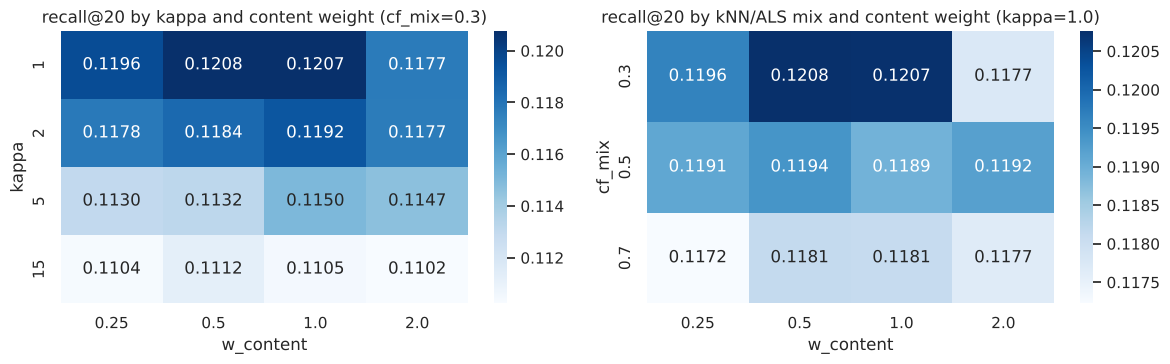

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
best = table.iloc[0]
t = table[(table.w_pop == best.w_pop) & (table.cf_mix == best.cf_mix)]
sns.heatmap(t.pivot(index="kappa", columns="w_content", values="recall@20"), annot=True, fmt=".4f", cmap="Blues", ax=axes[0])
axes[0].set_title(f"recall@20 by kappa and content weight (cf_mix={best.cf_mix})")
t = table[(table.w_pop == best.w_pop) & (table.kappa == best.kappa)]
sns.heatmap(t.pivot(index="cf_mix", columns="w_content", values="recall@20"), annot=True, fmt=".4f", cmap="Blues", ax=axes[1])
axes[1].set_title(f"recall@20 by kNN/ALS mix and content weight (kappa={best.kappa})")
plt.tight_layout(); plt.savefig(FIG / "06_hybrid_grid.png"); plt.show()

Then the playlist-side confidence $\\kappa_u$, on short (3-seed) validation playlists, where it matters:

In [4]:
short, short_users = short_playlists(train)
sv = short_users[np.isin(short_users, val_users)]
ku = tune(hybrid, short, val, sv, {"kappa_user": [0, 5, 20, 60, 150, 400]})
print(ku.to_string(index=False))
print("chosen:", {k: hybrid.__dict__[k] for k in ["kappa", "cf_mix", "w_content", "w_pop", "kappa_user"]})

 kappa_user  recall@20
        400   0.061840
        150   0.060389
         20   0.058293
         60   0.058197
          0   0.058099
          5   0.058073
chosen: {'kappa': np.int64(1), 'cf_mix': np.float64(0.3), 'w_content': np.float64(0.5), 'w_pop': np.float64(0.0), 'kappa_user': np.int64(400)}


## 2. How the soft router weighs a track

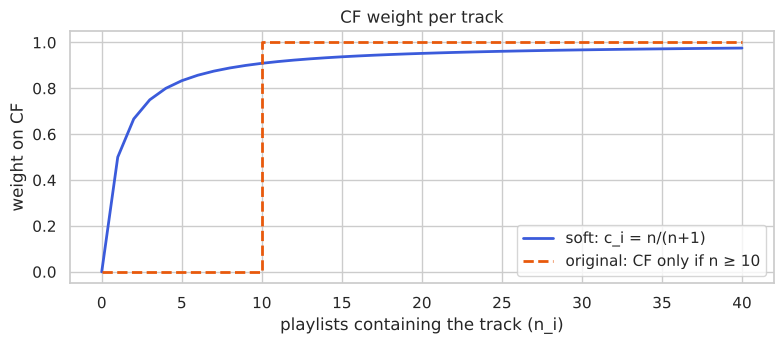

tracks the original router would send to content only (n_i < 10): 78%


In [5]:
x = np.arange(0, 41)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(x, x / (x + hybrid.kappa), color="#3b5bdb", lw=2, label=f"soft: c_i = n/(n+{hybrid.kappa:g})")
ax.step(x, (x >= 10).astype(float), where="post", color="#e8590c", lw=2, ls="--", label="original: CF only if n ≥ 10")
ax.set(xlabel="playlists containing the track (n_i)", ylabel="weight on CF", title="CF weight per track")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "06_cf_weight.png"); plt.show()
print(f"tracks the original router would send to content only (n_i < 10): {(n_i < 10).mean():.0%}")

With realistic long-tail data, most of the catalog sits below the original threshold of 10, so
the hard router ranked most tracks by content and threw away their (few, but informative) plays.

## 3. Validation: hybrid vs its parts vs the original router

In [6]:
router = HardThresholdRouter(als, content, pop).fit(train)
cands = {"Popularity": pop, "Content": content, "Item-kNN": knn, "ALS": als,
         "Original hard router": router, "Hybrid": hybrid}
seen = train
warm = {n: evaluate(m, train, val, users=val_users, ks=(10, 20)) for n, m in cands.items()}
shortv = {n: evaluate(m, short, val, users=sv, ks=(10, 20)) for n, m in cands.items()}
summary = pd.DataFrame({"warm recall@20": {n: r["recall@20"] for n, r in warm.items()},
                        "3-seed recall@20": {n: r["recall@20"] for n, r in shortv.items()}}).round(4)
summary

,warm recall@20,3-seed recall@20
Popularity,0.0061,0.0061
Content,0.0707,0.0521
Item-kNN,0.1126,0.0419
ALS,0.1113,0.0725
Original hard router,0.0539,0.0061
Hybrid,0.1181,0.0618


On warm playlists the hybrid beats every single model and more than doubles the original router.
On 3-seed playlists ALS alone is better on validation; the hybrid sits between ALS and kNN, and
the best playlist-confidence value is at the top of the grid, so the blend would still gain from
leaning even harder on ALS for short playlists. The original router collapses on 3-seed playlists
(0.006, the same as popularity) because it ignores the seeds and returns the global top list.

## 4. New releases (item cold start), one example

Tracks in `cold_items` were never in training, so CF gives every one of them the same score.
For the hybrid, $c_i = 0$ and the score falls back to content. Below: one new release and the
playlists the hybrid would add it to. Measured results on all new releases are in notebook 07,
on the test split.

In [7]:
meta = pd.read_csv(config.PLAYLISTS)
cold = splits["cold_items"]
probe = cold[np.argmax(tracks.popularity.values[cold])]
t = tracks.iloc[probe]
print(f"new release: {t.track_name} - {t.main_artist}  genres: {', '.join(t.genres)}  (training plays: {n_i[probe]:.0f})")
S = hybrid.score(train[val_users])[:, probe]
top = val_users[np.argsort(-S)[:8]]
actually = set(splits["cold_test"][:, probe].nonzero()[0])
out = meta.iloc[top][["playlist_name", "taste_genres"]].assign(added_it_in_test=[u in actually for u in top])
out

new release: Caile - Luar La L  genres: latin, latino, reggae, reggaeton  (training plays: 0)


,playlist_name,taste_genres,added_it_in_test
5999,Reggaeton & Songwriter Mix #5999,reggaeton;songwriter,False
1321,Reggae & IDM Mix #1321,reggae;idm,False
2295,Reggae Mix #2295,reggae,False
4394,Turkish & Latino Mix #4394,turkish;latino,False
2977,Reggae & IDM Mix #2977,reggae;idm,False
2228,Reggae & Latino Mix #2228,reggae;latino;idm,False
5305,Reggaeton Mix #5305,reggaeton,False
5529,Reggaeton & Reggae Mix #5529,reggaeton;reggae;songwriter,False


The playlists picked for this new release all share its scene (reggae, reggaeton, Latin), even though the model never saw a single play of it. None of these eight happened to add it in the held-out data; notebook 07 measures how often this works across all 1,824 new releases.

In [8]:
(config.DATA_PROCESSED / "hybrid_params.json").write_text(json.dumps(
    {k: float(hybrid.__dict__[k]) for k in ["kappa", "cf_mix", "w_content", "w_pop", "kappa_user"]}, indent=2))
print("saved hybrid_params.json")

saved hybrid_params.json
